# Predicting March Madness Success
**Cole DiGregorio** · CPSC 4300 Course Project (rebuilt and extended)

March Madness is a spectacle that captures everyone from die-hard college sports fans to casual bracket-fillers.
Many wonder what characteristics in a team lead to resounding March Madness success. Specifically, can we
predict the likelihood of a team making it deep into the tournament based on its offensive and defensive performance?

This notebook rebuilds the original course project, whose files were lost, and extends it. The original paper is in
[`docs/course_project.md`](docs/course_project.md), and the decisions that had to be inferred are listed in
[`docs/RECONSTRUCTION.md`](docs/RECONSTRUCTION.md). Numbers labeled *Original paper* come from the paper;
every other number is produced by this notebook.

**Contents**
1. Data cleaning
2. K-Means clustering
3. Predictive models (logistic regression)
4. Team lookup: where does a team fall, and what are its chances?
5. Other things worth noting
6. Results and discussion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

plt.rcParams.update({"figure.figsize": (8, 6), "font.size": 11, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Data cleaning
In order to analyze these questions, a large amount of data was needed. The *March Madness Historical Dataset*
by Jonathan Pilafas on Kaggle was used, which compiles KenPom advanced metrics for every NCAA Division I men's
basketball team. Version 31 of the dataset is saved in `data/` so the results can be reproduced.

The two characteristics focused on during this study were adjusted offensive efficiency (points scored per 100
possessions) and adjusted defensive efficiency (points allowed per 100 possessions). Both are adjusted for the
strength of the opponent, which better explains a team's true offensive and defensive efficiency.
These calculations were made by KenPom.

In [2]:
df = pd.read_csv("data/march_madness_kaggle_v31.csv")
print(df.shape)

df = df[["Season", "Mapped ESPN Team Name", "Seed",
         "Adjusted Offensive Efficiency", "Adjusted Offensive Efficiency Rank",
         "Adjusted Defensive Efficiency", "Adjusted Defensive Efficiency Rank",
         "Pre-Tournament.AdjOE", "Pre-Tournament.AdjDE",
         "Post-Season Tournament", "Final Four?", "Tournament Championship?", "Tournament Winner?"]]
df = df.rename(columns={"Mapped ESPN Team Name": "Team",
                        "Adjusted Offensive Efficiency": "AdjOE",
                        "Adjusted Offensive Efficiency Rank": "OffRank",
                        "Adjusted Defensive Efficiency": "AdjDE",
                        "Adjusted Defensive Efficiency Rank": "DefRank",
                        "Pre-Tournament.AdjOE": "PreAdjOE",
                        "Pre-Tournament.AdjDE": "PreAdjDE"})
df.head()

(8680, 179)


,Season,Team,Seed,AdjOE,OffRank,AdjDE,DefRank,PreAdjOE,PreAdjDE,Post-Season Tournament,Final Four?,Tournament Championship?,Tournament Winner?
0,2025,Duke,1,130.1,1,90.8,5,127.954,89.7995,March Madness,No,No,No
1,2026,Duke,1,128.0,4,89.1,2,NaN,NaN,March Madness,No,No,No
2,2026,Arizona,1,127.7,5,90.0,3,NaN,NaN,March Madness,No,No,No
3,2026,Michigan,1,126.6,8,89.0,1,NaN,NaN,March Madness,No,No,No
4,2015,Kentucky,1,121.3,6,84.4,1,121.270,83.8367,March Madness,Yes,No,No


The study spans 2003 to 2024. There was no tournament in 2020 because of COVID-19. A copy of the full data is
kept in `df_all` so the 2025 tournament can be used as a test later on.

In [3]:
df_all = df.copy()
years = [y for y in range(2003, 2025) if y != 2020]
df = df[df["Season"].isin(years)]
print(len(years), "tournaments,", len(df), "team-seasons (all of Division I)")

21 tournaments, 7271 team-seasons (all of Division I)


Since the dataset includes every Division I team, the next major part of cleaning the data was removing teams
not in the tournament. A list of every tournament team for each year was compiled, and any team not in the
list for its respective year was removed.

In [4]:
tourney_teams = (df[df["Post-Season Tournament"] == "March Madness"]
                 .groupby("Season")["Team"].apply(set).to_dict())

tourney = df[df.apply(lambda row: row["Team"] in tourney_teams[row["Season"]], axis=1)]
tourney = tourney.drop_duplicates(subset=["Season", "Team"]).reset_index(drop=True)
tourney["Seed"] = tourney["Seed"].astype(int)

print(len(tourney), "tournament team-seasons")
print(tourney.groupby("Season").size().to_dict())
print("Missing values:", tourney[["AdjOE", "AdjDE"]].isna().sum().sum())

1402 tournament team-seasons
{2003: 65, 2004: 65, 2005: 65, 2006: 65, 2007: 65, 2008: 65, 2009: 65, 2010: 65, 2011: 68, 2012: 68, 2013: 68, 2014: 68, 2015: 67, 2016: 68, 2017: 68, 2018: 68, 2019: 68, 2021: 68, 2022: 68, 2023: 67, 2024: 68}
Missing values: 0


Similarly, another data frame contains the sets of Sweet 16 teams, Elite Eight teams, Final Four teams,
championship game teams (the final two), and champions for each year. The Final Four, championship game, and
champions come from the dataset. The Sweet 16 and Elite Eight are not in the dataset, so they were compiled in
`data/sweet_sixteen.csv` and `data/elite_eight.csv` from Sports-Reference brackets.

In [5]:
sweet_sixteen = pd.read_csv("data/sweet_sixteen.csv")
elite_eight = pd.read_csv("data/elite_eight.csv")

results = pd.DataFrame({
    "Sweet 16":          sweet_sixteen.groupby("Season")["Team"].apply(set),
    "Elite Eight":       elite_eight.groupby("Season")["Team"].apply(set),
    "Final Four":        tourney[tourney["Final Four?"] == "Yes"].groupby("Season")["Team"].apply(set),
    "Championship Game": tourney[tourney["Tournament Championship?"] == "Yes"].groupby("Season")["Team"].apply(set),
    "Champion":          tourney[tourney["Tournament Winner?"] == "Yes"].groupby("Season")["Team"].apply(set),
})
results.head()

,Sweet 16,Elite Eight,Final Four,Championship Game,Champion
Season,,,,,
2003,"{Maryland, Texas, Notre Dame, Auburn, Butler, ...","{Texas, Marquette, Michigan State, Arizona, Ke...","{Kansas, Texas, Syracuse, Marquette}","{Kansas, Syracuse}",{Syracuse}
2004,"{Oklahoma State, Texas, Duke, Saint Joseph's, ...","{Oklahoma State, Duke, Saint Joseph's, Xavier,...","{Oklahoma State, Georgia Tech, UConn, Duke}","{Georgia Tech, UConn}",{UConn}
2005,"{Oklahoma State, Louisville, Duke, West Virgin...","{Louisville, West Virginia, Michigan State, Ar...","{Michigan State, North Carolina, Louisville, I...","{North Carolina, Illinois}",{North Carolina}
2006,"{Wichita State, Texas, Boston College, Bradley...","{Texas, Memphis, Florida, LSU, UCLA, UConn, Vi...","{LSU, Florida, UCLA, George Mason}","{Florida, UCLA}",{Florida}
2007,"{Oregon, Texas A&M, Georgetown, Butler, Memphi...","{Oregon, Georgetown, Memphis, Florida, UCLA, K...","{Florida, UCLA, Georgetown, Ohio State}","{Florida, Ohio State}",{Florida}


In [6]:
# 1/0 target columns: did this team reach each round?
rounds = ["Sweet 16", "Elite Eight", "Final Four", "Championship Game", "Champion"]
for col in rounds:
    tourney[col] = tourney.apply(lambda row: int(row["Team"] in results.loc[row["Season"], col]), axis=1)

print(tourney[rounds].sum().to_dict())

# sanity check: every team that reached a round also reached the round before it
for earlier, later in zip(rounds, rounds[1:]):
    assert (tourney[later] <= tourney[earlier]).all(), later

{'Sweet 16': 336, 'Elite Eight': 168, 'Final Four': 84, 'Championship Game': 42, 'Champion': 21}


## 2. K-Means clustering
The first method for analyzing the data was K-Means clustering, an unsupervised machine-learning algorithm used
to cluster similar points together. The goal for using K-Means was to separate teams into three distinct groups
based only on offensive and defensive efficiency. The model does not use tournament outcomes to create the
clusters, which allows statistical profiles that correlate to deeper tournament runs to appear naturally.

In [7]:
X = tourney[["AdjOE", "AdjDE"]]
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
raw_labels = kmeans.fit_predict(X)

# K-Means numbers its clusters arbitrarily. Renumber them by net efficiency (AdjOE - AdjDE) of each
# cluster center so the numbering is stable: 0 = weakest, 2 = strongest. Uses only the centers.
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["AdjOE", "AdjDE"])
order = (centers["AdjOE"] - centers["AdjDE"]).sort_values().index
mapping = {old: new for new, old in enumerate(order)}
tourney["Cluster"] = pd.Series(raw_labels).map(mapping)

centers.index = centers.index.map(mapping)
centers = centers.sort_index()
centers["Teams"] = tourney["Cluster"].value_counts().sort_index()
centers.round(1)

,AdjOE,AdjDE,Teams
0,105.0,102.9,339
1,110.8,93.0,568
2,117.3,97.0,495


To make the charts easier to read, the background of each chart is shaded by the cluster that any point in that
area would be assigned to. The defensive efficiency axis is also flipped, since a lower number is better on
defense. This way, the best teams are always in the **top right** of every chart.

In [8]:
colors = {0: "#d62728", 1: "#1f77b4", 2: "#2ca02c"}       # red, blue, green
shade = {0: "#fbe3e3", 1: "#e1ecf7", 2: "#e3f3e1"}        # light versions for the background
round_colors = ["#b0b0b0", "#808080", "#555555", "#2b2b2b", "gold"]   # light to dark gray, gold for champion
x_range, y_range = (88, 132), (82, 117)

# Ask K-Means which cluster every point on a fine grid belongs to, then color the background with it
xx, yy = np.meshgrid(np.linspace(75, 145, 400), np.linspace(70, 130, 400))
grid = pd.DataFrame({"AdjOE": xx.ravel(), "AdjDE": yy.ravel()})
zz = pd.Series(kmeans.predict(grid)).map(mapping).values.reshape(xx.shape)

def draw_clusters(ax):
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=[shade[0], shade[1], shade[2]])
    ax.set_xlim(x_range)
    ax.set_ylim(y_range[1], y_range[0])   # flipped so better defense is higher
    ax.set_xlabel("Adjusted Offensive Efficiency")
    ax.set_ylabel("Adjusted Defensive Efficiency\n(flipped: better defense is higher)")

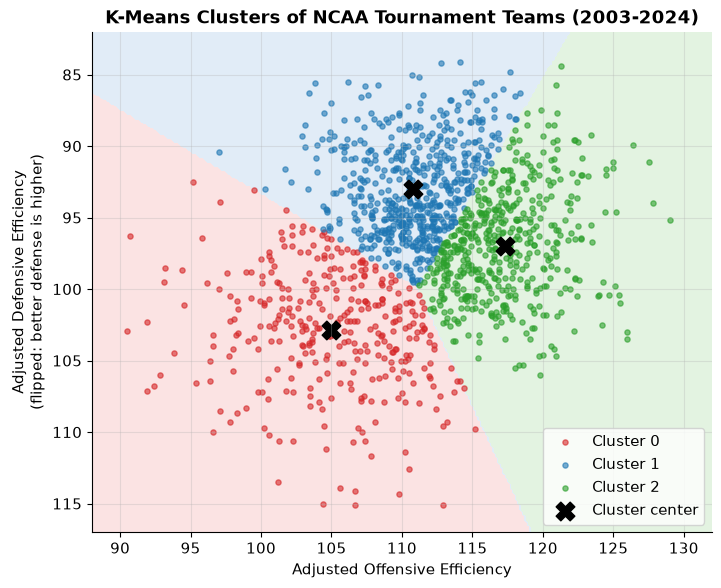

In [9]:
fig, ax = plt.subplots(figsize=(8, 6.5))
draw_clusters(ax)
for c in [0, 1, 2]:
    group = tourney[tourney["Cluster"] == c]
    ax.scatter(group["AdjOE"], group["AdjDE"], c=colors[c], s=14, alpha=0.6, label=f"Cluster {c}")
ax.scatter(centers["AdjOE"], centers["AdjDE"], marker="X", c="black", s=180, label="Cluster center")
ax.set_title("K-Means Clusters of NCAA Tournament Teams (2003-2024)", fontweight="bold")
ax.legend(loc="lower right")
plt.savefig("figures/figure1_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1**: K-Means clustering of NCAA Division 1 men's tournament teams according to adjusted offensive and
defensive efficiency. Each X marks the center of a cluster.

Each round of the tournament was then overlaid to analyze the relationship between the clusters and tournament
success. Each panel shows every tournament team in gray, and highlights the teams that reached that round in the
color of their cluster.

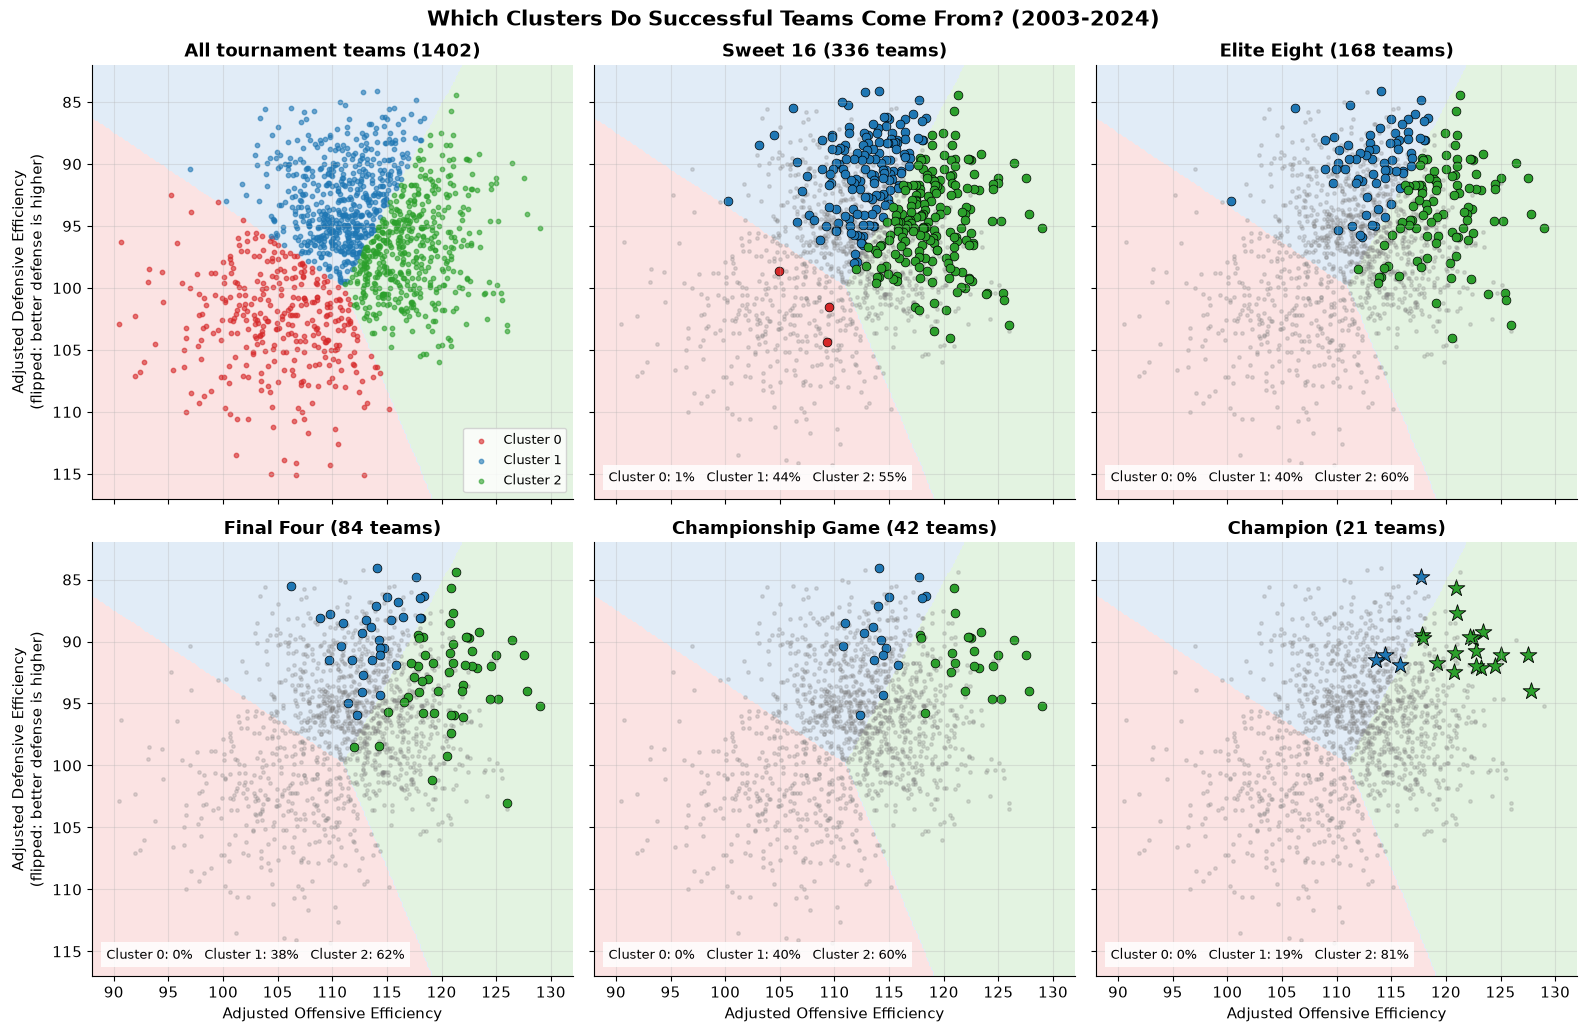

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5), sharex=True, sharey=True)
axes = axes.ravel()

draw_clusters(axes[0])
for c in [0, 1, 2]:
    group = tourney[tourney["Cluster"] == c]
    axes[0].scatter(group["AdjOE"], group["AdjDE"], c=colors[c], s=10, alpha=0.6, label=f"Cluster {c}")
axes[0].set_title(f"All tournament teams ({len(tourney)})", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=9)

for ax, r in zip(axes[1:], rounds):
    draw_clusters(ax)
    ax.scatter(tourney["AdjOE"], tourney["AdjDE"], c="gray", s=6, alpha=0.25)
    reached = tourney[tourney[r] == 1]
    for c in [0, 1, 2]:
        group = reached[reached["Cluster"] == c]
        if r == "Champion":
            ax.scatter(group["AdjOE"], group["AdjDE"], c=colors[c], marker="*", s=160, edgecolors="black", linewidths=0.6)
        else:
            ax.scatter(group["AdjOE"], group["AdjDE"], c=colors[c], s=40, edgecolors="black", linewidths=0.5)
    pct = reached["Cluster"].value_counts(normalize=True).reindex([0, 1, 2], fill_value=0) * 100
    ax.set_title(f"{r} ({len(reached)} teams)", fontweight="bold")
    ax.text(0.03, 0.04, f"Cluster 0: {pct[0]:.0f}%   Cluster 1: {pct[1]:.0f}%   Cluster 2: {pct[2]:.0f}%",
            transform=ax.transAxes, fontsize=9, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))

for ax in axes:
    ax.label_outer()
fig.suptitle("Which Clusters Do Successful Teams Come From? (2003-2024)", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.savefig("figures/figure2_clusters_by_round.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2**: K-Means clustering of NCAA Division 1 men's tournament teams, with the teams that reached the
Sweet 16, Elite Eight, Final Four, championship game, and the champions highlighted. Visually, the deeper a round
goes, the more its teams are pulled toward the top right of the chart and into Cluster 2.

How are the successful teams spread across the clusters? The original paper only looked at the Elite Eight,
Final Four, and champions, so the Sweet 16 and championship game have no original numbers to compare against.

In [11]:
paper = {"Elite Eight": [0, 40.0, 60.0], "Final Four": [0, 39.8, 60.2], "Champion": [0, 38.1, 61.9]}

rows = []
for col in rounds:
    counts = tourney[tourney[col] == 1]["Cluster"].value_counts().reindex([0, 1, 2], fill_value=0)
    pct = counts / counts.sum() * 100
    for c in [0, 1, 2]:
        rows.append({"Round": col, "Cluster": c, "Teams": counts[c], "Rebuilt %": round(pct[c], 1),
                     "Original paper %": paper[col][c] if col in paper else "not in paper"})
distribution = pd.DataFrame(rows)
distribution

,Round,Cluster,Teams,Rebuilt %,Original paper %
0,Sweet 16,0,3,0.9,not in paper
1,Sweet 16,1,147,43.8,not in paper
2,Sweet 16,2,186,55.4,not in paper
3,Elite Eight,0,0,0.0,0
4,Elite Eight,1,68,40.5,40.0
5,Elite Eight,2,100,59.5,60.0
6,Final Four,0,0,0.0,0
7,Final Four,1,32,38.1,39.8
8,Final Four,2,52,61.9,60.2
9,Championship Game,0,0,0.0,not in paper


Three Cluster 0 teams reached the Sweet 16, but none went any further. The table below looks at it the other
way: out of every team in a cluster, how many went on to reach each round? This is the more useful view when
filling out a bracket.

In [12]:
tourney[(tourney["Cluster"] == 0) & (tourney["Sweet 16"] == 1)][["Season", "Team", "Seed", "AdjOE", "AdjDE"]]

,Season,Team,Seed,AdjOE,AdjDE
1113,2023,Princeton,15,109.5,101.5
1156,2013,Florida Gulf Coast,15,104.9,98.6
1194,2021,Oral Roberts,15,109.3,104.4


In [13]:
success_rate = (tourney.groupby("Cluster")[rounds].mean() * 100).round(1)
success_rate.insert(0, "Teams", tourney["Cluster"].value_counts().sort_index())
success_rate

,Teams,Sweet 16,Elite Eight,Final Four,Championship Game,Champion
Cluster,,,,,,
0,339,0.9,0.0,0.0,0.0,0.0
1,568,25.9,12.0,5.6,3.0,0.7
2,495,37.6,20.2,10.5,5.1,3.4


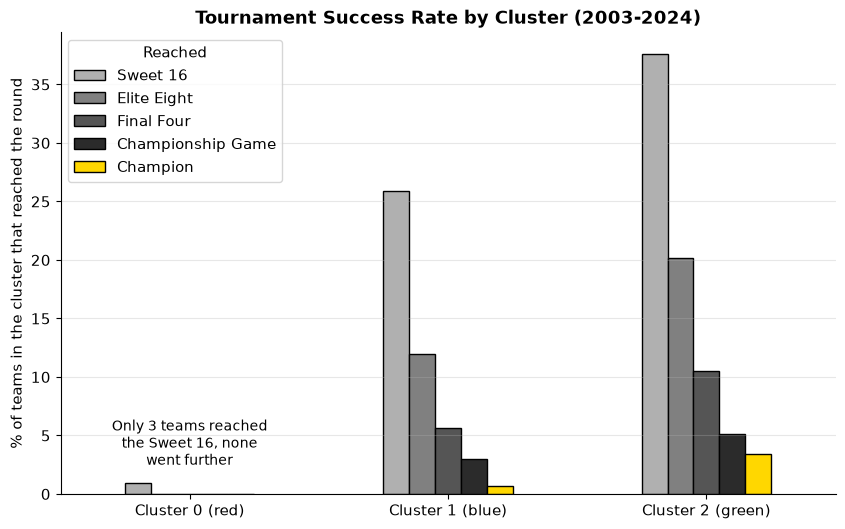

In [14]:
ax = success_rate[rounds].plot(kind="bar", color=round_colors, edgecolor="black", rot=0, figsize=(10, 6))
ax.set_xticklabels(["Cluster 0 (red)", "Cluster 1 (blue)", "Cluster 2 (green)"])
ax.set_xlabel("")
ax.set_ylabel("% of teams in the cluster that reached the round")
ax.set_title("Tournament Success Rate by Cluster (2003-2024)", fontweight="bold")
ax.text(0, 2.5, "Only 3 teams reached\nthe Sweet 16, none\nwent further", ha="center", fontsize=10)
ax.grid(axis="x", visible=False)
ax.legend(title="Reached")
plt.savefig("figures/figure3_success_by_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3**: Percent of teams in each cluster that reached each round. A Cluster 2 team was almost twice as
likely as a Cluster 1 team to reach the Elite Eight, and about five times as likely to win the title.

## 3. Predictive models (logistic regression)
The second method used was logistic regression, a supervised learning algorithm for binary classification.
The original project trained three models (Elite Eight, Final Four, and champion). Here, two more were added, so
there is one model for each round: Sweet 16, Elite Eight, Final Four, championship game, and champion. Each model
uses the same two features, offensive and defensive efficiency, and outputs a probability from 0 to 1. Each model
is trained on 80% of the tournament teams and evaluated on the remaining 20%.

In [15]:
X = tourney[["AdjOE", "AdjDE"]]
models = {}
eval_rows = []
for target in rounds:
    y = tourney[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    models[target] = model
    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    eval_rows.append({"Model": target,
                      "Teams that advanced (test set)": int(y_test.sum()),
                      "Correctly picked": tp,
                      "Missed": fn,
                      "False alarms": fp,
                      "Recall": round(tp / (tp + fn), 2),
                      "Accuracy": round(accuracy_score(y_test, y_pred), 3),
                      "Accuracy if always guessing 'no'": round(1 - y_test.mean(), 3)})

evaluation = pd.DataFrame(eval_rows).set_index("Model")
evaluation

,Teams that advanced (test set),Correctly picked,Missed,False alarms,Recall,Accuracy,Accuracy if always guessing 'no'
Model,,,,,,,
Sweet 16,57,33,24,20,0.58,0.843,0.797
Elite Eight,28,9,19,11,0.32,0.893,0.900
Final Four,12,1,11,5,0.08,0.943,0.957
Championship Game,5,0,5,0,0.00,0.982,0.982
Champion,1,0,1,0,0.00,0.996,0.996


The accuracy looks high, but the last column shows why it is misleading: a "model" that simply guesses that no
team ever advances would score about the same. For the Elite Eight and Final Four, the models are actually
slightly *less* accurate than always guessing "no". Recall, the share of teams that actually advanced which the
model correctly picked, tells the real story. The Sweet 16 model catches a little more than half of the Sweet 16
teams, but the deeper the round, the fewer teams the model is willing to pick. The championship game and champion
models never pick a single team, since so few teams ever reach those rounds.

In [16]:
paper_coefs = {"Elite Eight": (0.2981, -0.3063), "Final Four": (0.2990, -0.3166), "Champion": (0.4557, -0.4046)}

coef_rows = []
for target in rounds:
    m = models[target]
    coef_rows.append({"Model": target,
                      "AdjOE coef": round(m.coef_[0][0], 4),
                      "AdjDE coef": round(m.coef_[0][1], 4),
                      "Odds change per +1 AdjOE": f"{(np.exp(m.coef_[0][0]) - 1) * 100:+.1f}%",
                      "Odds change per +1 AdjDE": f"{(np.exp(m.coef_[0][1]) - 1) * 100:+.1f}%",
                      "Original paper AdjOE": paper_coefs[target][0] if target in paper_coefs else "not in paper",
                      "Original paper AdjDE": paper_coefs[target][1] if target in paper_coefs else "not in paper"})
coefs = pd.DataFrame(coef_rows).set_index("Model")
coefs

,AdjOE coef,AdjDE coef,Odds change per +1 AdjOE,Odds change per +1 AdjDE,Original paper AdjOE,Original paper AdjDE
Model,,,,,,
Sweet 16,0.2967,-0.3107,+34.5%,-26.7%,not in paper,not in paper
Elite Eight,0.3076,-0.3327,+36.0%,-28.3%,0.2981,-0.3063
Final Four,0.3114,-0.3524,+36.5%,-29.7%,0.299,-0.3166
Championship Game,0.4054,-0.4327,+50.0%,-35.1%,not in paper,not in paper
Champion,0.4444,-0.4079,+55.9%,-33.5%,0.4557,-0.4046


The coefficient represents the change in the log odds of reaching a round for a one-point increase in
efficiency. The odds columns convert it into something easier to read: the percent change in a team's odds for
each extra point. Every model shows the same pattern: a higher offensive efficiency raises the odds, and a
higher defensive efficiency (allowing more points) lowers them. In general, the later the round, the bigger
the effect.

**Check (not part of the original project):** the original train/test split is unknown, so this shows how much
the original three models' coefficients move across 50 different random splits.

In [17]:
spread = []
for target in ["Elite Eight", "Final Four", "Champion"]:
    for seed in range(50):
        X_train, X_test, y_train, y_test = train_test_split(X, tourney[target], test_size=0.2, random_state=seed)
        m = LogisticRegression(max_iter=1000).fit(X_train, y_train)
        spread.append({"Model": target, "AdjOE coef": m.coef_[0][0], "AdjDE coef": m.coef_[0][1]})
pd.DataFrame(spread).groupby("Model", sort=False).agg(["min", "median", "max"]).round(3)

AdjOE coef               AdjDE coef              
                   min median    max        min median    max
Model                                                        
Elite Eight      0.285  0.307  0.333     -0.333 -0.301 -0.266
Final Four       0.251  0.296  0.336     -0.362 -0.299 -0.264
Champion         0.342  0.461  0.684     -0.604 -0.404 -0.353

### Flaws of the predictive models
These models are not meant to be accurate bracket predictors, and it is important to understand why.

- **Each round's model is trained on its own.** The Final Four model does not know about the Elite Eight model,
  so nothing forces the chances to go down from round to round. The check below counts how often a team's
  predicted chances come out in the wrong order.
- **Only two features.** The models ignore seeding, matchups, the path through the bracket, injuries, and luck.
- **Very few positive examples.** There are only 42 championship game teams and 21 champions, so the later
  models are built on a small number of teams.
- **The chances are not shared out across the field.** Each team is scored on its own, so the chances of all
  68 teams do not add up to what they should (for example, 1 champion per year). This is shown in the 2025 test
  in section 5.
- **End-of-season numbers.** The models are trained on efficiency numbers that include tournament games, which
  slightly favors teams that went deep.

In [18]:
probs = pd.DataFrame({r: models[r].predict_proba(X)[:, 1] for r in rounds})
out_of_order = (probs.diff(axis=1).iloc[:, 1:] > 0).any(axis=1)
print("Teams whose predicted chances go UP from one round to the next:", out_of_order.sum(), "of", len(probs))

Teams whose predicted chances go UP from one round to the next: 0 of 1402


For the real tournament teams, the chances always go down from round to round, which is a good sign. However,
this is only because the five models happen to agree with each other, and nothing in the models guarantees it.

## 4. Team lookup: where does a team fall, and what are its chances?
`where_is_team` takes any team's adjusted offensive and defensive efficiency (KenPom lists these as AdjO and AdjD)
and shows where that team falls on the cluster chart, next to the predicted chance of it reaching each round.
To try a team, change the numbers in the cells below.

In [19]:
def where_is_team(adj_oe, adj_de, name="Your team", save_as=None):
    team = pd.DataFrame({"AdjOE": [adj_oe], "AdjDE": [adj_de]})
    cluster = int(mapping[kmeans.predict(team)[0]])
    chances = pd.Series({r: models[r].predict_proba(team)[0, 1] for r in rounds})

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.2, 1]})

    # Left: the team on the cluster chart, next to every past tournament team and champion
    draw_clusters(ax1)
    ax1.scatter(tourney["AdjOE"], tourney["AdjDE"], c="gray", s=8, alpha=0.3, label="Tournament teams 2003-2024")
    champs = tourney[tourney["Champion"] == 1]
    ax1.scatter(champs["AdjOE"], champs["AdjDE"], c="gold", marker="*", s=90, edgecolors="black",
                linewidths=0.5, label="Past champions")
    ax1.scatter(adj_oe, adj_de, c=colors[cluster], marker="*", s=600, edgecolors="black", linewidths=1.5, label=name)
    ax1.set_xlim(min(x_range[0], adj_oe - 2), max(x_range[1], adj_oe + 2))
    ax1.set_ylim(max(y_range[1], adj_de + 2), min(y_range[0], adj_de - 2))
    ax1.set_title(f"{name} falls in Cluster {cluster}", fontweight="bold")
    ax1.legend(loc="lower right", fontsize=9, markerscale=0.6)

    # Right: predicted chance of reaching each round
    bars = ax2.barh(rounds[::-1], chances[rounds[::-1]] * 100, color=round_colors[::-1], edgecolor="black")
    for bar, p in zip(bars, chances[rounds[::-1]]):
        ax2.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2, f"{p:.0%}", va="center")
    ax2.set_xlim(0, 110)
    ax2.set_xlabel("Predicted chance (%)")
    ax2.set_title(f"Predicted chance of reaching each round", fontweight="bold")
    ax2.grid(axis="y", visible=False)

    fig.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()
    return (chances * 100).round(1).rename("Predicted chance (%)").to_frame()

**Example 1:** 2025 Florida, using its pre-tournament numbers (Florida went on to win the 2025 title).

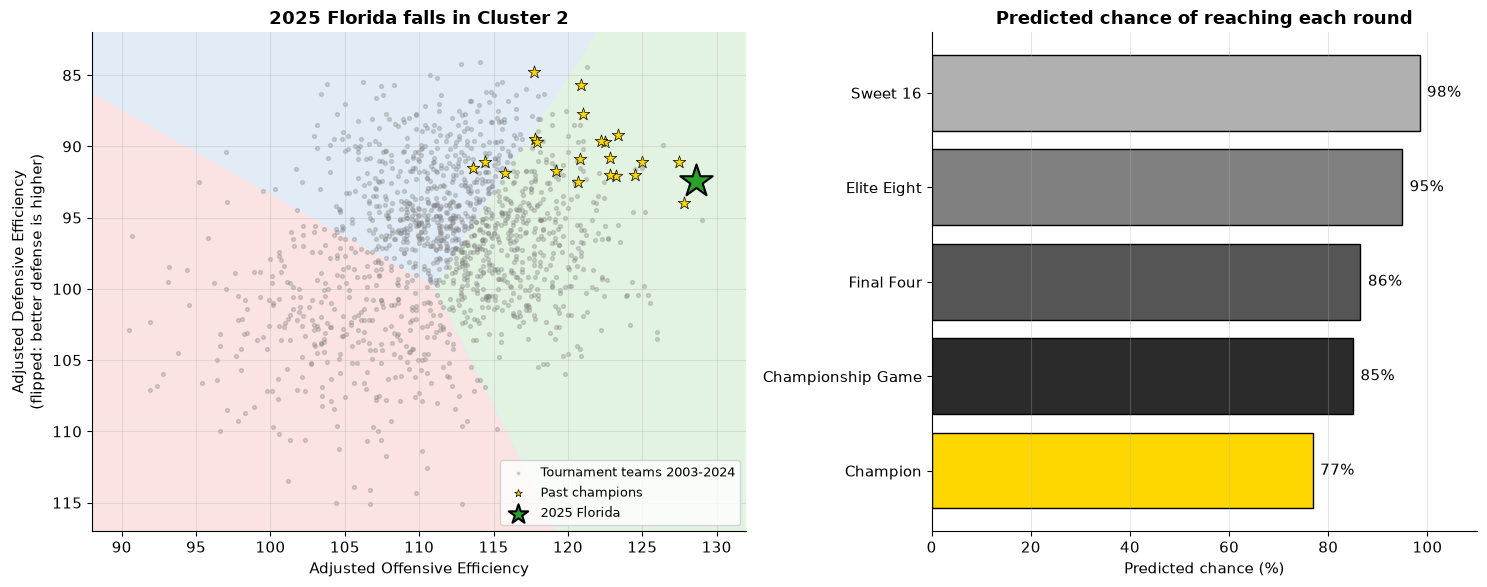

,Predicted chance (%)
Sweet 16,98.4
Elite Eight,94.9
Final Four,86.5
Championship Game,85.0
Champion,76.9


In [20]:
florida = df_all[(df_all["Season"] == 2025) & (df_all["Team"] == "Florida")].iloc[0]
where_is_team(florida["PreAdjOE"], florida["PreAdjDE"], "2025 Florida", save_as="figures/figure4_team_lookup.png")

**Figure 4**: 2025 Florida's pre-tournament efficiency placed on the cluster chart (left) and its predicted chance
of reaching each round (right).

**Example 2:** a team with the average offensive and defensive efficiency of all tournament teams.

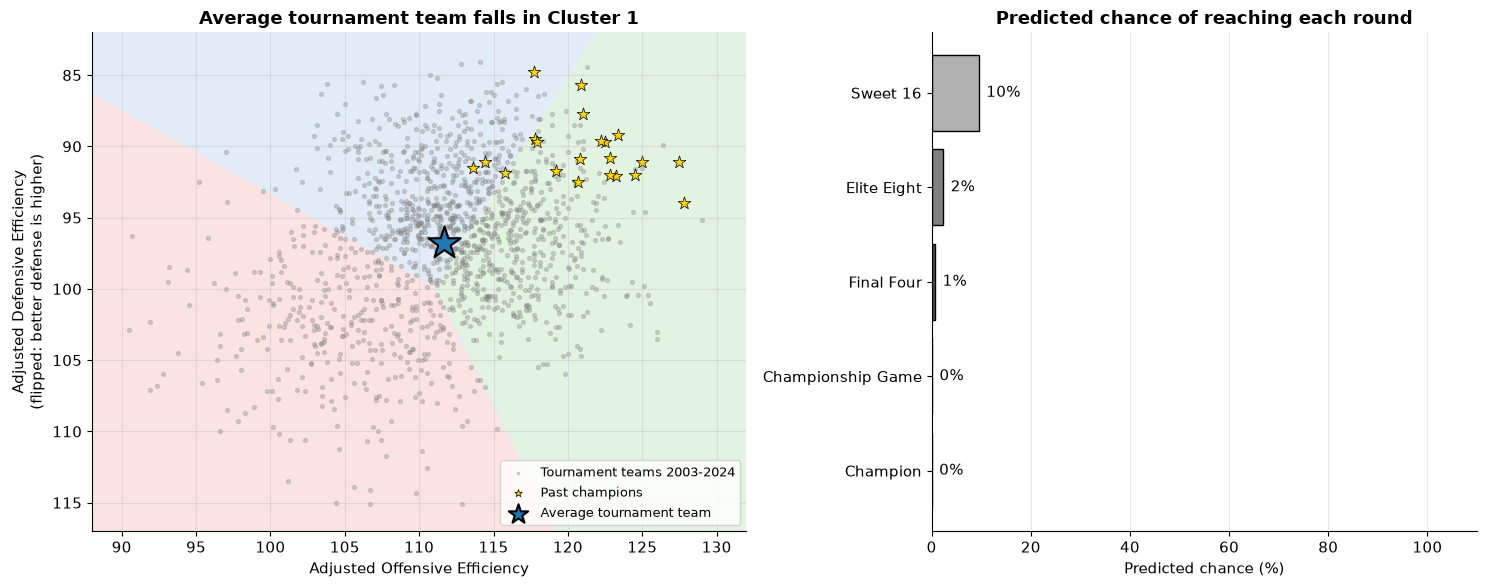

,Predicted chance (%)
Sweet 16,9.5
Elite Eight,2.3
Final Four,0.7
Championship Game,0.1
Champion,0.0


In [21]:
where_is_team(tourney["AdjOE"].mean(), tourney["AdjDE"].mean(), "Average tournament team")

**Try your own team:** replace the numbers below with any team's AdjO and AdjD from KenPom.

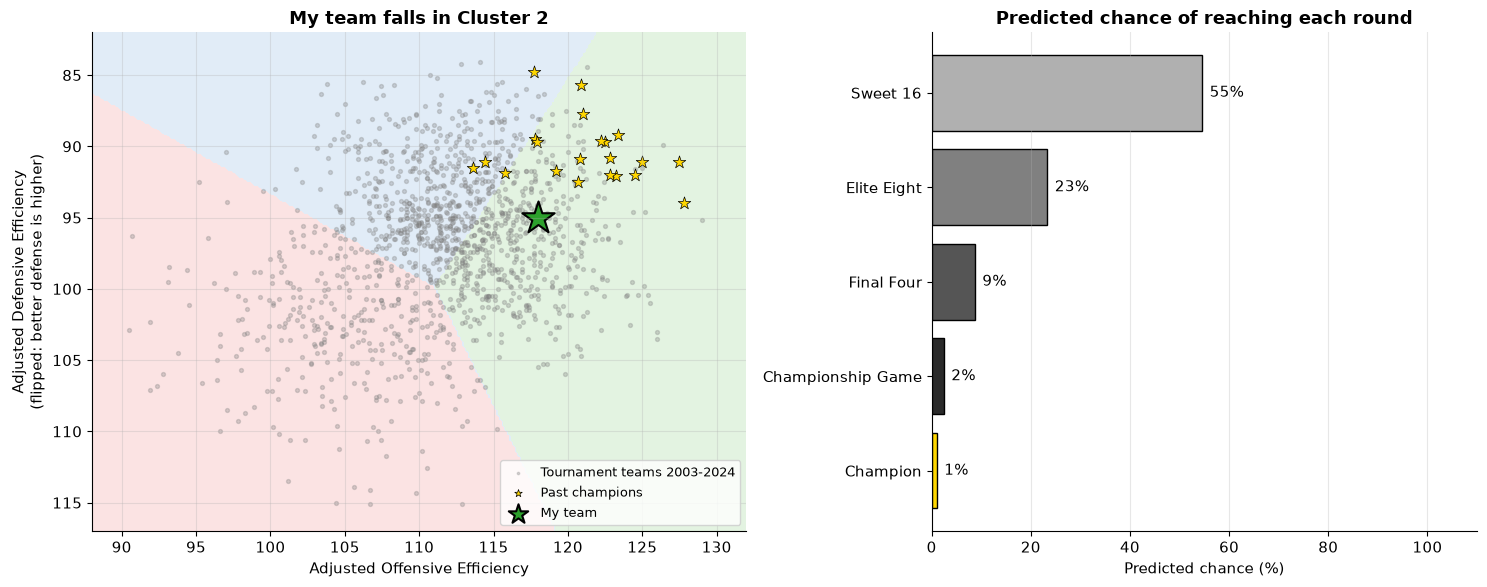

,Predicted chance (%)
Sweet 16,54.6
Elite Eight,23.4
Final Four,8.7
Championship Game,2.5
Champion,1.0


In [22]:
where_is_team(adj_oe=118.0, adj_de=95.0, name="My team")

## 5. Other things worth noting
These were not part of the original project. They use the same data and the same models to look at a few
questions that came up while rebuilding it.

### 5.1 What did the champions look like?
KenPom also ranks every Division I team (around 350 each year) in offensive and defensive efficiency.

In [23]:
champs = tourney[tourney["Champion"] == 1][["Season", "Team", "Seed", "AdjOE", "OffRank", "AdjDE", "DefRank", "Cluster"]]
champs = champs.sort_values("Season").reset_index(drop=True)
both_top25 = (champs["OffRank"] <= 25) & (champs["DefRank"] <= 25)
print("Champions ranked top 25 in both offense and defense:", both_top25.sum(), "of", len(champs))
print("Champions ranked top 25 in defense:", (champs["DefRank"] <= 25).sum(), "of", len(champs))
champs

Champions ranked top 25 in both offense and defense: 20 of 21
Champions ranked top 25 in defense: 21 of 21


,Season,Team,Seed,AdjOE,OffRank,AdjDE,DefRank,Cluster
0,2003,Syracuse,3,114.4,17,91.1,14,1
1,2004,UConn,2,117.8,9,89.5,6,2
2,2005,North Carolina,1,122.5,2,89.7,5,2
3,2006,Florida,3,117.9,3,89.7,7,2
4,2007,Florida,1,122.8,1,92.0,13,2
5,2008,Kansas,1,120.9,2,85.7,1,2
6,2009,North Carolina,1,123.2,1,92.1,18,2
7,2010,Duke,1,121.0,1,87.7,5,2
8,2011,UConn,3,115.8,19,91.9,15,1
9,2012,Kentucky,1,122.2,2,89.6,7,2


20 of the 21 champions ranked in the top 25 nationally in both offensive and defensive efficiency, and all 21
ranked in the top 25 in defense. The one exception is 2014 UConn, a 7 seed whose offense ranked 39th.
Thus, while a champion does not need the best offense or the best defense, it almost never has a weakness on
either end of the court.

### 5.2 Cinderella teams
Which teams reached the Elite Eight with the weakest numbers? Net efficiency (offensive minus defensive
efficiency) is used as a single measure of team strength.

In [24]:
tourney["Net"] = tourney["AdjOE"] - tourney["AdjDE"]
cinderellas = tourney[tourney["Elite Eight"] == 1].nsmallest(8, "Net")
cinderellas[["Season", "Team", "Seed", "AdjOE", "AdjDE", "Net", "Cluster", "Final Four"]]

,Season,Team,Seed,AdjOE,AdjDE,Net,Cluster,Final Four
1131,2022,Saint Peter's,15,100.3,93.0,7.3,1,0
919,2011,VCU,11,112.0,98.5,13.5,2,1
852,2014,Dayton,11,113.8,99.6,14.2,2,0
801,2018,Kansas State,9,110.1,95.3,14.8,1,0
798,2022,Miami,10,113.9,99.1,14.8,2,0
788,2005,West Virginia,7,114.1,99.1,15.0,2,0
719,2024,NC State,11,114.3,98.4,15.9,2,1
668,2011,Butler,8,112.3,95.9,16.4,1,1


2022 Saint Peter's, a 15 seed, stands out as the weakest Elite Eight team by a wide margin, with a net efficiency
of 7.3 when no other Elite Eight team was below 13. Even so, Saint Peter's falls in Cluster 1, because its defense
was strong. VCU (2011) and NC State (2024) both reached the Final Four as 11 seeds. These teams are what make
March Madness so hard to predict, and no model based only on season-long efficiency would have picked them.

### 5.3 How do the clusters compare to seeding?
Seeds (1 to 16) are assigned by the selection committee, which looks at many of the same statistics.

In [25]:
tourney["Seed Group"] = pd.cut(tourney["Seed"], bins=[0, 4, 8, 12, 16], labels=["1-4", "5-8", "9-12", "13-16"])
pd.crosstab(tourney["Seed Group"], tourney["Cluster"])

Cluster,0,1,2
Seed Group,,,
1-4,1,138,196
5-8,0,183,154
9-12,28,201,130
13-16,310,46,15


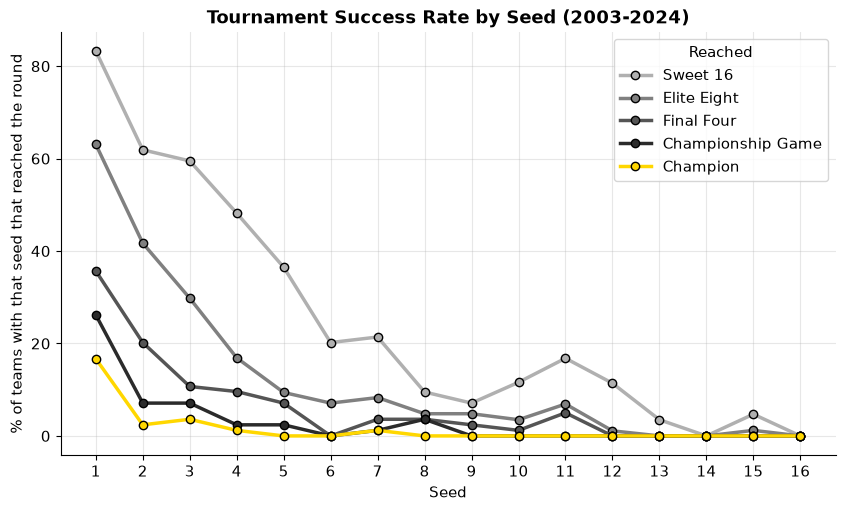

Seed,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
Sweet 16,83.3,61.9,59.5,48.2,36.5,20.2,21.4,9.5,7.1,11.6,16.8,11.4,3.5,0.0,4.7,0.0
Elite Eight,63.1,41.7,29.8,16.9,9.4,7.1,8.3,4.8,4.8,3.5,6.9,1.1,0.0,0.0,1.2,0.0
Final Four,35.7,20.2,10.7,9.6,7.1,0.0,3.6,3.6,2.4,1.2,5.0,0.0,0.0,0.0,0.0,0.0
Championship Game,26.2,7.1,7.1,2.4,2.4,0.0,1.2,3.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Champion,16.7,2.4,3.6,1.2,0.0,0.0,1.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
seed_rate = (tourney.groupby("Seed")[rounds].mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 5.5))
for r, color in zip(rounds, round_colors):
    ax.plot(seed_rate.index, seed_rate[r], marker="o", color=color, markeredgecolor="black", linewidth=2.5, label=r)
ax.set_xticks(range(1, 17))
ax.set_xlabel("Seed")
ax.set_ylabel("% of teams with that seed that reached the round")
ax.set_title("Tournament Success Rate by Seed (2003-2024)", fontweight="bold")
ax.legend(title="Reached")
plt.savefig("figures/figure5_success_by_seed.png", dpi=150, bbox_inches="tight")
plt.show()
seed_rate.T

**Figure 5**: Percent of teams with each seed that reached each round.

Cluster 0 is mostly made up of 13 to 16 seeds (310 of its 339 teams), which are usually champions of smaller
conferences that earn an automatic bid. This helps explain why no Cluster 0 team went past the Sweet 16, since
these teams also face the strongest opponents in the first rounds. Seeding is also a sharper signal than the
clusters: 1 seeds reached the Elite Eight 63.1% of the time, compared to 20.2% for Cluster 2 teams. This makes
sense because Cluster 2 holds about 24 teams per year, while there are only four 1 seeds.

### 5.4 Testing the models on the 2025 tournament
The models were trained on 2003 to 2024, so the 2025 tournament is a fair test they have never seen. In order to
make the test realistic, the 2025 numbers used are the **pre-tournament** efficiencies, which is what a fan would
actually have when filling out a bracket. The 2025 results were added by hand in `data/results_2025.csv`, since
the dataset does not include them yet. (2026 could not be tested because its pre-tournament numbers are missing.)

For each round, the model's picks are the teams it gave the highest chances: its top 16 for the Sweet 16, top 8
for the Elite Eight, and so on.

In [27]:
t25 = df_all[(df_all["Season"] == 2025) & (df_all["Post-Season Tournament"] == "March Madness")].copy()
t25["Seed"] = t25["Seed"].astype(int)
X_2025 = t25[["PreAdjOE", "PreAdjDE"]].rename(columns={"PreAdjOE": "AdjOE", "PreAdjDE": "AdjDE"})

t25["Cluster"] = [mapping[c] for c in kmeans.predict(X_2025)]
for target in rounds:
    t25["P(" + target + ")"] = models[target].predict_proba(X_2025)[:, 1].round(3)

actual = pd.read_csv("data/results_2025.csv")
actual.columns = ["Team"] + ["Actual " + r for r in rounds]
t25 = t25.merge(actual, on="Team", how="left")
for r in rounds:
    t25["Actual " + r] = t25["Actual " + r].fillna(0).astype(int)

test_rows = []
for r, n in zip(rounds, [16, 8, 4, 2, 1]):
    picks = t25.nlargest(n, "P(" + r + ")")
    test_rows.append({"Round": r, "Model's picks": n, "Picks that were correct": int(picks["Actual " + r].sum()),
                      "Sum of predicted chances": round(t25["P(" + r + ")"].sum(), 1),
                      "Teams that actually reached it": int(t25["Actual " + r].sum())})
pd.DataFrame(test_rows).set_index("Round")

,Model's picks,Picks that were correct,Sum of predicted chances,Teams that actually reached it
Round,,,,
Sweet 16,16,10,24.4,16
Elite Eight,8,8,14.0,8
Final Four,4,4,8.2,4
Championship Game,2,1,5.5,2
Champion,1,0,4.1,1


In [28]:
cols = ["Team", "Seed", "Cluster"] + ["P(" + r + ")" for r in rounds] + ["Actual Champion"]
t25.sort_values("P(Champion)", ascending=False).head(10)[cols]

,Team,Seed,Cluster,P(Sweet 16),P(Elite Eight),P(Final Four),P(Championship Game),P(Champion),Actual Champion
0,Duke,1,2,0.991,0.973,0.930,0.932,0.880,0
2,Florida,1,2,0.984,0.949,0.865,0.850,0.769,1
3,Auburn,1,2,0.978,0.928,0.813,0.778,0.677,0
1,Houston,1,2,0.982,0.944,0.861,0.828,0.671,0
4,Tennessee,2,2,0.936,0.813,0.607,0.449,0.241,0
5,Alabama,2,2,0.902,0.712,0.437,0.288,0.195,0
8,Texas Tech,3,2,0.839,0.577,0.296,0.156,0.097,0
7,Gonzaga,8,2,0.808,0.525,0.257,0.123,0.069,0
6,Michigan State,2,2,0.832,0.582,0.323,0.155,0.064,0
11,Iowa State,3,2,0.803,0.526,0.269,0.121,0.054,0


The model picked 10 of the 16 Sweet 16 teams, all eight Elite Eight teams, and all four Final Four teams. Its top
champion pick was Duke, while the actual champion, Florida, had the second-highest chance. Its two championship
game picks were Duke and Florida, so it got one of the two finalists right (Houston was the other).

However, 2025 was an unusually predictable tournament: all four 1 seeds reached the Final Four, so simply picking
the top seeds would have done almost as well. One tournament is not enough to say the models work this well in
general. The "Sum of predicted chances" column also shows the flaw described in section 3: the champion chances
of all 68 teams add up to well over 1, even though only one team can win.

Interestingly, 47 of the 68 teams in 2025 fell in Cluster 2, compared to about 24 per year before. This is
because offensive efficiency has risen over time: the average tournament team's offensive efficiency was 109.9 in
2003 and 116.2 in 2025. Since the clusters were built from all of the years together, newer teams are more
likely to land in the high-offense cluster.

In [29]:
print("2025 tournament teams per cluster:", t25["Cluster"].value_counts().sort_index().to_dict())
print("Average offensive efficiency of tournament teams:",
      df_all[df_all["Post-Season Tournament"] == "March Madness"].groupby("Season")["AdjOE"].mean().round(1)[[2003, 2025]].to_dict())

2025 tournament teams per cluster: {0: 16, 1: 5, 2: 47}
Average offensive efficiency of tournament teams: {2003: 109.9, 2025: 116.2}


## 6. Results and discussion

In [30]:
# Rebuilt results next to the original paper's (the paper did not cover the Sweet 16 or championship game)
compare = distribution[distribution["Round"].isin(paper)]
summary = compare[compare["Cluster"] > 0].pivot(index="Round", columns="Cluster", values=["Rebuilt %", "Original paper %"])
summary = summary.reindex(["Elite Eight", "Final Four", "Champion"])
summary.columns = [f"{name}, Cluster {c}" for name, c in summary.columns]
summary

,"Rebuilt %, Cluster 1","Rebuilt %, Cluster 2","Original paper %, Cluster 1","Original paper %, Cluster 2"
Round,,,,
Elite Eight,40.5,59.5,40.0,60.0
Final Four,38.1,61.9,39.8,60.2
Champion,19.0,81.0,38.1,61.9


**K-Means.** The model separated the tournament teams into three clusters with clear profiles. Cluster 0 (red)
shows low offensive and weak defensive efficiency, Cluster 1 (blue) shows moderate offensive efficiency and the
strongest defensive efficiency, and Cluster 2 (green) shows the highest offensive efficiency with good defensive
efficiency. The most obvious conclusion is that no team in Cluster 0 reached the Elite Eight from 2003 to 2024,
the same result as the original paper. Only three Cluster 0 teams reached the Sweet 16. This suggests that teams
with below-average efficiencies are unlikely to make a deep run in the tournament.

The deeper the round, the more its teams come from Cluster 2: 55% of Sweet 16 teams, about 60% of Elite Eight,
Final Four, and championship game teams, and 81% of champions. About 60% of Elite Eight and Final Four teams
falling in Cluster 2 matches the original paper. For champions, the rebuilt results are more lopsided than the
paper (81% compared to 61.9%). One difference from the paper is that Cluster 2's average defense is not the
strongest of the three; Cluster 1's is. Thus, the rebuilt clusters point even more toward elite offense, paired
with good defense, as the profile of a champion.

**Logistic regression.** All five models show the same trend as the original paper: higher offensive efficiency
increases the likelihood of tournament success, and lower defensive efficiency also increases it. The later the
round, the larger the weight on both, reinforcing the notion that championship teams must excel on both ends of
the court. The rebuilt coefficients for the original three models are within about 0.04 of the paper's.

The models show high accuracy, but mainly because most teams do not advance; guessing "no" for every team scores
about the same, and even slightly better for the Elite Eight and Final Four. When it comes to identifying the actual successful teams, the models struggle, especially in the
later rounds, because there are so few of those teams to learn from.

**Other findings.** Almost every champion (20 of 21) ranked in the top 25 nationally in both offense and defense.
The low-efficiency cluster is mostly made up of 13 to 16 seeds, so seeding and efficiency tell a similar story,
although seeding is the sharper of the two. Cinderella teams like 2022 Saint Peter's show the limits of any
model built only on efficiency. On the 2025 tournament, which the models never saw, the models picked 10 of the
16 Sweet 16 teams and every Elite Eight and Final Four team, but 2025 was an unusually predictable year.

**Limitations.** K-Means assumes clusters are spherical and does not account for tournament outcomes. The
logistic models reduce the tournament to yes/no outcomes, are each trained on their own, ignore matchups and
seeding, and assume a linear relationship between efficiency and the log odds of success. The efficiency numbers
are end-of-season values, so they include tournament games, which slightly favors teams that went deep. Finally,
offensive efficiency has risen over the years, so combining 20 seasons into one set of clusters places more
recent teams in the high-offense cluster.

**Conclusion.** Offensive and defensive efficiency are key indicators of March Madness success. While these
models cannot give perfect predictions, they help identify potential contenders and serve as a useful filter
when filling out a bracket.